# Spatial follow-up of m/z 774.25–774.50

Map the strongest window from notebook 03 using all measured pixels. Compare
mouse-level summaries after excluding progressively wider bands around the
edges and gaps of the measured footprints. These bands are defined by
geometry. Anatomical comparisons require verified histology matches and
region labels.

In [1]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

root = Path.cwd().resolve()
if not (root / "pyproject.toml").exists():
    root = root.parent
assert (root / "pyproject.toml").exists(), "Open the notebook from the repository."
sys.path.insert(0, str(root / "src"))
from cardiac_aging.inspection import load_config

config = load_config(root)
workspace = Path.home() / "Documents/Codex/2026-11-03/can-x20"
features = Path(os.environ.get("CARDIAC_MSI_FEATURES", str(workspace / "work/full-msi")))
histology = Path(os.environ.get("CARDIAC_HISTOLOGY", str(Path.home() / "Downloads/HistoBilder")))
registration = Path(os.environ.get("CARDIAC_REGISTRATION", str(workspace / "outputs")))
results = root / config["results_dir"]
results.mkdir(parents=True, exist_ok=True)
samples = pd.read_csv(root / config["sample_sheet"], dtype={"measurement_id": str})
assert len(samples) == samples["animal_id"].nunique() == 12
assert samples["age_group"].value_counts().to_dict() == {"young": 6, "old": 6}
lower, upper = 774.25, 774.50


def interior_mask(mask, pixels):
    # Repeated 3×3 erosion excludes measured outer edges and edges of holes.
    for _ in range(pixels):
        padded = np.pad(mask, 1)
        height, width = mask.shape
        mask = np.logical_and.reduce([
            padded[y:y + height, x:x + width] for y in range(3) for x in range(3)
        ])
    return mask


cohort, records = [], []
for mouse in samples.itertuples(index=False):
    folder = features / mouse.measurement_id
    info = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    with np.load(folder / "axes_and_native_mean.npz") as metadata:
        xy, edges = metadata["xy"], metadata["bin_edges"]
    i, = np.flatnonzero((edges[:-1] == lower) & (edges[1:] == upper))
    data = np.load(folder / "pixel_binned_intensity.npy", mmap_mode="r")
    if (info["preview"] or info["source"] != mouse.imzml_filename
            or len(xy) != info["pixels_declared"] or len(xy) != info["pixels_processed"]
            or data.shape != (len(xy), len(edges) - 1)):
        raise ValueError(f"Expected a complete export for {mouse.measurement_id}")
    signal = np.array(data[:, i])
    if not np.isfinite(signal).all():
        raise ValueError(f"Non-finite values for {mouse.measurement_id}")
    x, y = (xy - xy.min(axis=0)).T
    ion_map = np.full((y.max() + 1, x.max() + 1), np.nan, dtype=np.float32)
    ion_map[y, x] = signal
    mask = np.isfinite(ion_map)
    if mask.sum() != len(signal):
        raise ValueError(f"Duplicate coordinates for {mouse.measurement_id}")
    inside3 = interior_mask(mask, 3)
    inside6 = interior_mask(inside3, 3)
    boundary = mask & ~inside3
    groups = {"whole": mask, "boundary_3px": boundary,
              "interior_3px": inside3, "interior_6px": inside6}
    if not all(region.any() for region in groups.values()):
        raise ValueError(f"An edge or interior band is empty for {mouse.measurement_id}")
    record = {"measurement_id": mouse.measurement_id, "age_group": mouse.age_group,
              "boundary_fraction": boundary.sum() / mask.sum()}
    for name, region in groups.items():
        record[f"{name}_pixels"] = int(region.sum())
        record[name] = ion_map[region].mean(dtype=np.float64)
    records.append(record)
    cohort.append({"mouse": mouse, "map": ion_map, "xy": xy, "signal": signal})
summary = pd.DataFrame(records)
reference_fraction = summary["boundary_fraction"].mean()
summary["common_boundary_fraction"] = (
    reference_fraction * summary["boundary_3px"]
    + (1 - reference_fraction) * summary["interior_3px"]
)
summary.to_csv(results / "spatial_774_mouse_summary.csv", index=False)
columns = ["whole", "boundary_3px", "interior_3px", "interior_6px", "common_boundary_fraction"]
comparison = summary.groupby("age_group")[columns].mean().T[["young", "old"]]
comparison["old_minus_young"] = comparison["old"] - comparison["young"]
comparison["relative_difference_pct"] = 100 * comparison["old_minus_young"] / comparison["young"]
comparison.to_csv(results / "spatial_774_group_summary.csv")
display(comparison.round(3))
print(f"Mapped {summary['whole_pixels'].sum():,} measured pixels.")

age_group,young,old,old_minus_young,relative_difference_pct
whole,10.510,13.177,2.667,25.375
boundary_3px,10.530,11.881,1.351,12.830
interior_3px,10.513,13.291,2.778,26.422
interior_6px,10.518,13.366,2.848,27.079
common_boundary_fraction,10.515,13.184,2.669,25.388


Mapped 1,038,886 measured pixels.


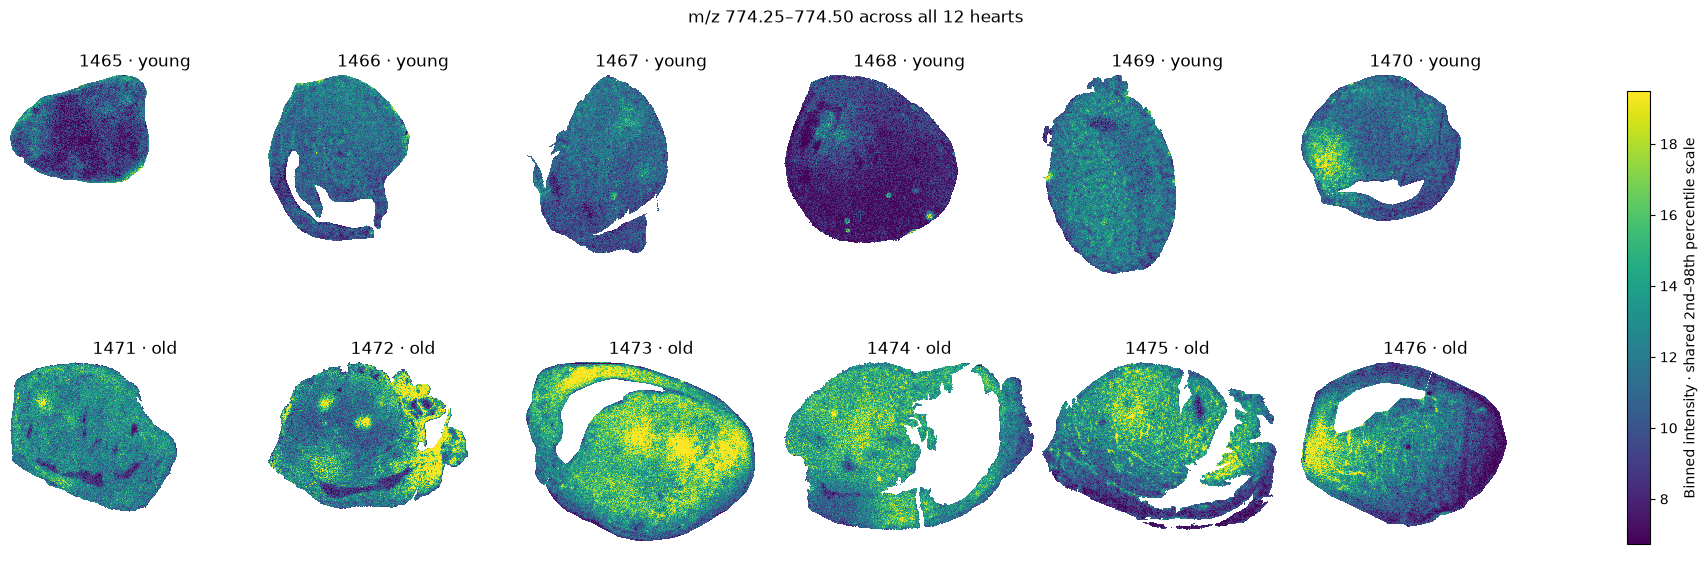

In [7]:
vmin, vmax = np.percentile(np.concatenate([m["signal"] for m in cohort]), [2, 98])
norm = Normalize(vmin, vmax, clip=True)
cmap = plt.get_cmap("viridis").with_extremes(bad="white")
fig, axes = plt.subplots(2, 6, figsize=(17, 6), layout="constrained")
width = max(item["map"].shape[1] for item in cohort)
height = max(item["map"].shape[0] for item in cohort)
for row_index, group in enumerate(("young", "old")):
    for ax, item in zip(axes[row_index], (m for m in cohort if m["mouse"].age_group == group)):
        plot = ax.imshow(item["map"], cmap=cmap, norm=norm, interpolation="nearest")
        ax.set(xlim=(-.5, width - .5), ylim=(height - .5, -.5),
               title=f"{item['mouse'].measurement_id} · {group}")
        ax.set_axis_off()
fig.suptitle(f"m/z {lower:.2f}–{upper:.2f} across all 12 hearts")
fig.colorbar(plot, ax=axes, shrink=.8, label="Binned intensity · shared 2nd–98th percentile scale")
fig.savefig(results / "spatial_774_full_cohort.png", dpi=170)
plt.show()


## Histology overlays for review

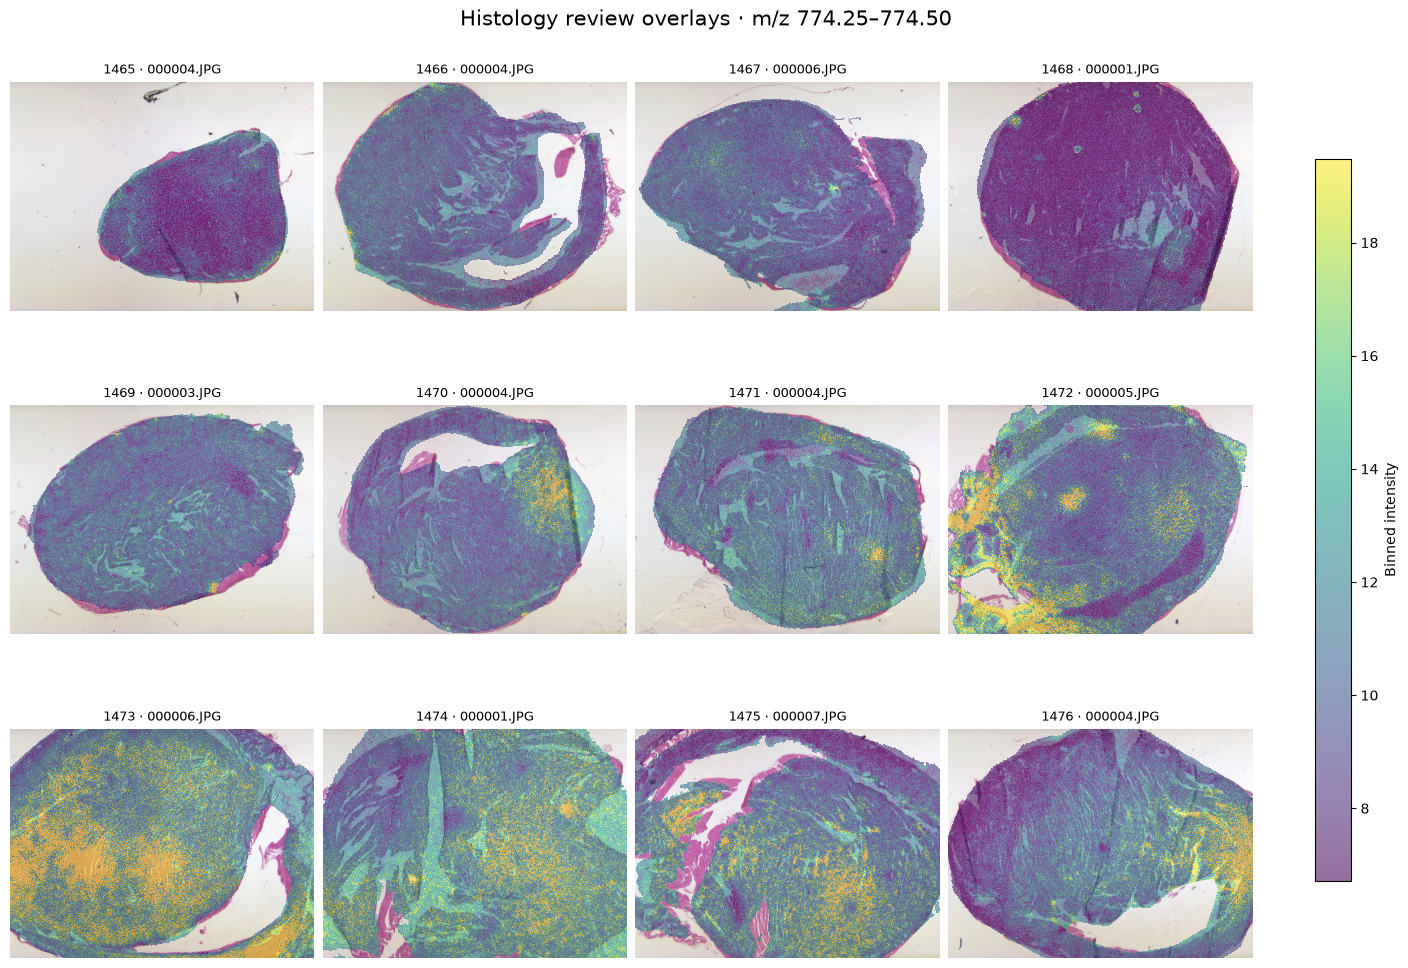

In [9]:
ranked = json.loads((registration / "histology_outline_candidates.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(3, 4, figsize=(14, 10), layout="constrained")
for ax, item in zip(axes.flat, cohort):
    mouse = item["mouse"].measurement_id
    entry = ranked["mice"][mouse][0]
    filename = entry["filename"]
    path = histology / f"Jule_Herz_Frankfurt_HE_{mouse}" / filename
    with Image.open(path) as original:
        photo = ImageOps.exif_transpose(original).convert("RGB")
    matrix = np.asarray(entry["matrix"])
    shift = np.asarray(entry["shift"])
    # Map output photo coordinates to positions in the cropped MSI grid.
    inverse = np.linalg.inv(matrix)
    origin = item["xy"].min(axis=0)
    offset = -inverse @ shift - origin
    offset += .5 - inverse @ np.array([.5, .5])
    coefficients = np.column_stack((inverse, offset)).ravel()
    transformed = Image.fromarray(item["map"]).transform(
        photo.size, Image.Transform.AFFINE, coefficients,
        resample=Image.Resampling.NEAREST, fillcolor=float("nan"))
    image = np.asarray(transformed)
    ax.imshow(photo)
    # Show the original image where MSI has no measured pixel.
    overlay_cmap = plt.get_cmap("viridis").with_extremes(bad=(0, 0, 0, 0))
    plot = ax.imshow(image, cmap=overlay_cmap, norm=norm, alpha=.57, interpolation="nearest")
    ax.set_title(f"{mouse} · {filename}", fontsize=9)
    ax.set_axis_off()
fig.suptitle(f"Histology review overlays · m/z {lower:.2f}–{upper:.2f}", fontsize=15)
fig.colorbar(plot, ax=axes, shrink=.75, label="Binned intensity")
fig.savefig(results / "spatial_774_histology_review.png", dpi=170)
plt.show()